# Recognizing auditory events with residual blocks

We'll recognize spoken digits from timestamped auditory events, turning the recordings into frames before passing them through a residual SNN. We'll use a small subset to learn how the model trains, rather than aim for a state-of-the-art recognizer. This gives us a practical place to explore variable sequence lengths, synaptic filtering, varied decays, smooth firing, and parameter caching during evaluation.

After installing the repository, use `pip install -r examples/shd/requirements.txt`, then open `examples/shd/tutorial.ipynb`. The neighboring `main.py` runs the complete workflow. The first run downloads the full SHD source dataset to the shared `examples/data` folder, even though we'll train on a small subset, so the download can take much longer than training.

Source on GitHub: [notebook](https://github.com/Yegor-men/tracetorch/blob/main/examples/shd/tutorial.ipynb) and [complete program](https://github.com/Yegor-men/tracetorch/blob/main/examples/shd/main.py).

In [1]:
from pathlib import Path
from time import perf_counter
from torch.utils.data import DataLoader, Subset
import tonic
from tonic import transforms

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
import tracetorch as tt

# Keep saved figures readable regardless of the notebook editor's theme.
plt.style.use("default")
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cpu"
DATA_ROOT = Path("../data")
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)


## 1. Turning events into frames

Spiking Heidelberg Digits represents audio with 700 input neurons and 20 classes. Each event records when an input neuron fires, rather than storing a uniformly sampled waveform. We'll count those events in windows of 20,000 microseconds, or 20 milliseconds, to obtain one input vector per frame.

We'll select 1,024 training recordings and 256 separate test recordings, then frame those selected recordings once. Keeping these small sets in memory avoids reopening the HDF5 files and binning the same events again at every epoch. The setup uses the shared `../data` path when the notebook runs from `examples/shd`.

In [2]:
def collate_left_padded(samples):
    """Align recording endings and return events [T, B, 700] and labels [B]."""
    recordings, labels = zip(*samples)
    frames = [torch.as_tensor(recording).flatten(start_dim=1).float() for recording in recordings]
    longest = max(frame.shape[0] for frame in frames)
    batch = frames[0].new_zeros(longest, len(frames), frames[0].shape[-1])
    for index, frame in enumerate(frames):
        batch[-len(frame):, index] = frame
    return batch, torch.as_tensor(labels, dtype=torch.long)


def get_dataloaders(data_root, batch_size, train_samples, test_samples, time_window, seed):
    frame_transform = transforms.ToFrame(
        sensor_size=tonic.datasets.SHD.sensor_size, time_window=time_window,
    )
    train = tonic.datasets.SHD(data_root, train=True, transform=frame_transform)
    test = tonic.datasets.SHD(data_root, train=False, transform=frame_transform)
    generator = torch.Generator().manual_seed(seed)
    if train_samples:
        train = Subset(train, torch.randperm(len(train), generator=generator)[:train_samples].tolist())
    if test_samples:
        test = Subset(test, torch.randperm(len(test), generator=generator)[:test_samples].tolist())
    # Frame once: otherwise every epoch reopens HDF5 files and rebins the same events.
    train = [train[index] for index in range(len(train))]
    test = [test[index] for index in range(len(test))]
    return (
        DataLoader(train, batch_size=batch_size, shuffle=True, generator=generator,
                   collate_fn=collate_left_padded),
        DataLoader(test, batch_size=batch_size, collate_fn=collate_left_padded),
    )

Longest training recording: 60 frames
Frames: torch.Size([46, 32, 700]) Labels: torch.Size([32])


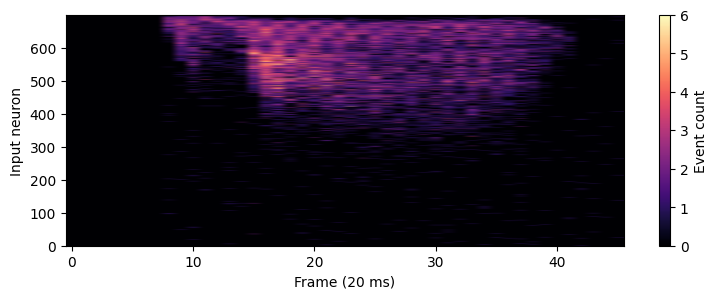

In [3]:
train_loader, test_loader = get_dataloaders(DATA_ROOT, 32, 1024, 256, 20000, seed=0)
sequence_steps = max(recording.shape[0] for recording, _ in train_loader.dataset)
print("Longest training recording:", sequence_steps, "frames")
events, labels = next(iter(test_loader))
print("Frames:", events.shape, "Labels:", labels.shape)
plt.figure(figsize=(9, 3))
plt.imshow(events[:, 0].T, origin="lower", aspect="auto", cmap="magma")
plt.xlabel("Frame (20 ms)")
plt.ylabel("Input neuron")
plt.colorbar(label="Event count")
plt.show()

The batch has shape `[T, B, 700]`, with time first and one event count per input neuron in each frame. The plot shows one recording across its channels, so we can see where the activity occurs before asking a model to classify it.

## 2. Aligning the ends of recordings

Different recordings contain different numbers of frames, but our batch still needs a rectangular tensor. Since we'll classify from the final timestep, we'll put the padding before shorter recordings. Their last real frames then line up with the end of the batch instead of being followed by extra silence.

Let's use two tiny recordings to see that alignment directly.

tensor([[0., 2.],
        [0., 2.],
        [1., 2.],
        [1., 2.],
        [1., 2.]])


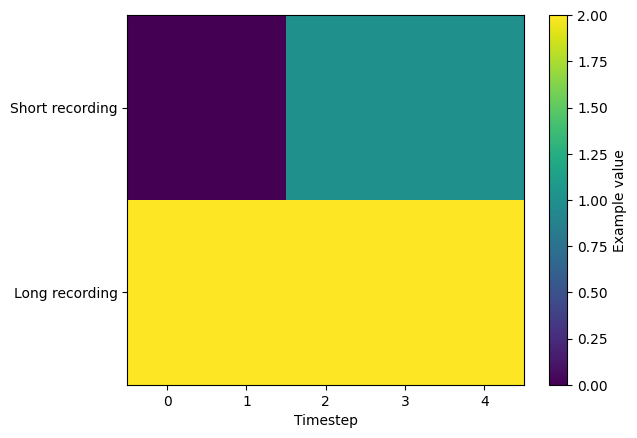

In [4]:
short = torch.ones(3, 1, 2)
long = torch.full((5, 1, 2), 2.0)
padded, _ = collate_left_padded([(short, 0), (long, 1)])
print(padded[:, :, 0])
plt.imshow(padded[:, :, 0].T, aspect="auto", cmap="viridis")
plt.yticks([0, 1], ["Short recording", "Long recording"])
plt.xlabel("Timestep")
plt.colorbar(label="Example value")
plt.show()

The short recording now begins with two zero frames followed by its three real frames, so both recordings finish together. This gives the final output the timing we intended, rather than asking it to survive a variable silent suffix.

Those leading zeros are still inputs, however. Biases and smooth firing can update states during the prefix, so aligning the endings doesn't by itself make a prediction independent of padding length. We'll retain this straightforward batching rule while keeping that behavior visible.

## 3. Choosing decays for the recordings

The selected training recordings contain at most 60 frames, or about 1.2 seconds at 20 ms per frame. We'll use their length to give the membrane traces a chance to retain early input until the final frame. Decay is still the parameter we initialize; a time horizon simply helps us choose its scale:

$$H=\frac{1}{1-\beta}, \qquad \beta=1-\frac{1}{H}.$$

For example, $\beta=0.9$ has horizon 10, while $\beta=0.99$ has horizon 100. The horizon is the total weight $\sum_{k=0}^{\infty}\beta^k$ of a passive exponential history, rather than a deadline after which information disappears. With no new input or reset, an old contribution retains the fraction $\beta^n$ after $n$ steps.

We'll draw an independent horizon for each feature between one and four times the longest training recording, then convert those values to decays. For 60 frames that gives decays from about 0.9833 to 0.9958. This range is an initialization choice, not a guarantee of memory: training can change it, and firing resets also affect the hidden neurons. The training split supplies the duration so we don't use test recordings to choose the initialization.

Let's plot passive traces for a few decays and see how much remains at the recording's end.

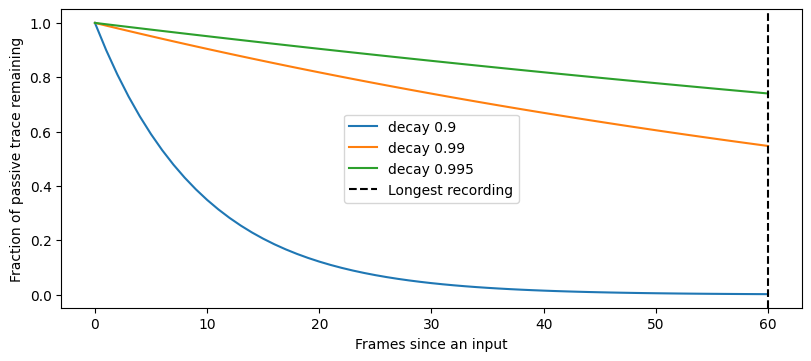

Sample membrane decay range: 0.9843795299530029 0.9958241581916809
A decay of 0.99 has horizon: 99.99999999999991
Its half-life in frames: 68.96756393652842


In [5]:
def sequence_decays(num_features, sequence_steps):
    """Initialize passive memory horizons between one and four recordings."""
    horizons = max(2, sequence_steps) * (1 + 3 * torch.rand(num_features))
    return tt.utils.convert_decay(horizons, "horizon", "decay")

steps = torch.arange(0, sequence_steps + 1)
fig, axis = plt.subplots(figsize=(8, 3.5), layout="constrained")
for decay in (0.9, 0.99, 0.995):
    axis.plot(steps, decay ** steps, label=f"decay {decay}")
axis.axvline(sequence_steps, color="black", linestyle="--", label="Longest recording")
axis.set_xlabel("Frames since an input")
axis.set_ylabel("Fraction of passive trace remaining")
axis.legend()
plt.show()

example_decays = sequence_decays(64, sequence_steps)
print("Sample membrane decay range:", example_decays.min().item(), example_decays.max().item())
print("A decay of 0.99 has horizon:", tt.utils.convert_decay(0.99, "decay", "horizon"))
print("Its half-life in frames:", tt.utils.convert_decay(0.99, "decay", "halflife"))

The 0.9 trace is nearly gone after 60 frames, while 0.99 still retains about 55% of an isolated input. The half-life conversion answers a more specific question: how many steps until a passive trace falls by half. We don't need it to configure the layer, but the utility is available when that is the duration we want to express.

## 4. Filtering events inside a residual block

An auditory event is brief, but nearby events can describe the same evolving sound. We'll introduce an SLIB neuron, which keeps a synaptic moving average $a_t$ before updating its membrane $m_t$:

$$a_t=\alpha a_{t-1}+(1-\alpha)u_t,$$
$$m_t=\beta(m_{t-1}-\theta s_{t-1})+a_t,\qquad
s_t=\sigma(4(m_t-\theta)).$$

Here $u_t$ is the projected input, $\theta$ is the positive firing threshold, and $s_{t-1}$ is the previous smooth firing output. Reset uses that previous output before membrane decay, just as in LIB. Each feature gets an independent synaptic decay from `torch.rand(width)`, giving many quick filters alongside a smaller number of slower ones. The membrane decays use the longer, duration-based initialization we just explored.

The residual block adds this history-dependent contribution to its current features:

$$y_t=x_t+W_{\mathrm{out}}s_t(W_{\mathrm{in}}x_t).$$

The linear modules also have biases, omitted from the equation for readability. One projection supplies the neuron's input and the other mixes its output back into the residual features. The identity path carries current input directly, while the neuron path can contribute information retained from earlier frames.

In [6]:
class ResidualBlock(nn.Module):
    def __init__(self, width, sequence_steps):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Linear(width, width),
            tt.snn.SLIB(
                width, alpha=torch.rand(width), beta=sequence_decays(width, sequence_steps),
                spike_fn=tt.snn.spike_fn.smooth,
            ),
            nn.Linear(width, width),
        )

    def forward(self, x):
        return x + self.branch(x)


class ResidualSNN(tt.Model):
    def __init__(self, width=64, sequence_steps=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(700, width),
            ResidualBlock(width, sequence_steps),
            ResidualBlock(width, sequence_steps),
            tt.snn.LI(width, beta=sequence_decays(width, sequence_steps)),
            nn.Linear(width, 20),
        )
        # The feature accumulator can sum dozens of frames before this readout.
        nn.init.normal_(self.net[-1].weight, std=0.01)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, events):
        return self.net(events)

The initial projection maps 700 event channels to 64 features. Two residual blocks process those features, then an LI layer retains 64 feature traces. A final linear projection reads those traces into 20 class scores.

This changes the role of LI from the MNIST model. Its values no longer correspond directly to classes: they are learned features with independent decays, and the final projection decides how their histories support each class. We initialize this projection with small weights because the LI can accumulate contributions over dozens of frames.

The hidden SLIB neurons use smooth firing, $s(z)=\sigma(4z)$, rather than hard binary events. Their continuous output also drives the delayed reset. The synaptic trace filters the event input first, while the membrane combines that filtered input with its own remaining charge.

## 5. Training from the final frame

As in the image example, we'll reset before an independent batch, retain states through its frames, and calculate cross-entropy from the last scores. The helper below keeps that timestep loop visible so we can see where the recording's history enters the prediction.

In [7]:
def forward_sequence(model, sequence):
    model.reset_states()
    for events in sequence:
        logits = model(events)
    return logits


def run_epoch(model, dataloader, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = total_correct = total_count = 0
    with torch.set_grad_enabled(training):
        for events, labels in dataloader:
            events, labels = events.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = forward_sequence(model, events)
            loss = F.cross_entropy(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.numel()
            total_correct += (logits.argmax(-1) == labels).sum().item()
            total_count += labels.numel()
    model.reset_states()
    return total_loss / total_count, total_correct / total_count

## 6. Caching transformed parameters for evaluation

Before running the full training loop, let's look at an evaluation operation that we'll use between epochs. A neuron decay is stored as a raw parameter and transformed with sigmoid when accessed. When the weights stay fixed, we can cache that transformed value instead of recalculating it on each timestep.

`compile_parameters()` creates those caches and temporarily freezes the registered transformed parameters, while keeping the raw parameter objects themselves. Ordinary linear weights aren't frozen by this operation. We'll compare outputs from identical reset states to check that caching preserves the calculation.

This serves a different purpose from `eval()`, which selects module evaluation behavior, and `no_grad()`, which stops gradient recording. We'll use all three where appropriate rather than relying on one to perform the others.

In [8]:
torch.manual_seed(0)
model = ResidualSNN(width=64, sequence_steps=sequence_steps).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
events, labels = next(iter(test_loader))
events = events.to(device)
model.eval()
with torch.no_grad():
    normal = forward_sequence(model, events)
model.compile_parameters()
try:
    print("Decay trainable while compiled:", model.net[1].branch[1].raw_beta.requires_grad)
    with torch.no_grad():
        compiled = forward_sequence(model, events)
finally:
    model.decompile_parameters()
print("Decay trainable afterward:", model.net[1].branch[1].raw_beta.requires_grad)
print("Maximum score difference:", (compiled - normal).abs().max().item())

Decay trainable while compiled: False
Decay trainable afterward: True
Maximum score difference: 0.0


The scores agree before and during compilation. After decompilation, the decay is trainable again, and the optimizer still refers to the same parameter objects. If we had deliberately fixed a parameter, decompilation would keep it fixed rather than enabling everything indiscriminately.

Caching these transforms may save only a small part of execution time, so this comparison checks behavior rather than promising a particular speedup. It also differs from PyTorch's `torch.compile`, which operates on computation graphs.

## 7. Training over the selected recordings

We can now put the evaluation procedure after each training epoch. The `try/finally` block restores the intended learnability even if evaluation fails, so the next epoch can use live parameters and the same optimizer again.

In [9]:
torch.manual_seed(0)
train_loader, test_loader = get_dataloaders(DATA_ROOT, 32, 1024, 256, 20000, seed=0)
sequence_steps = max(recording.shape[0] for recording, _ in train_loader.dataset)
model = ResidualSNN(width=64, sequence_steps=sequence_steps).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
loss, accuracy = run_epoch(model, test_loader, device)
history = {"train_loss": [], "test_loss": [loss], "test_accuracy": [accuracy]}
print(f"Before training: loss={loss:.3f}, accuracy={accuracy:.1%}")
started = perf_counter()
for epoch in range(1, 6):
    train_loss, _ = run_epoch(model, train_loader, device, optimizer)
    model.eval()
    model.compile_parameters()
    try:
        loss, accuracy = run_epoch(model, test_loader, device)
    finally:
        model.decompile_parameters()
    history["train_loss"].append(train_loss)
    history["test_loss"].append(loss)
    history["test_accuracy"].append(accuracy)
    print(f"Epoch {epoch}: loss={loss:.3f}, accuracy={accuracy:.1%}")
print(f"Training and evaluation: {perf_counter() - started:.1f}s")

Before training: loss=3.283, accuracy=5.5%
Epoch 1: loss=2.355, accuracy=27.7%
Epoch 2: loss=1.832, accuracy=32.4%
Epoch 3: loss=1.896, accuracy=35.9%
Epoch 4: loss=1.509, accuracy=50.8%
Epoch 5: loss=1.432, accuracy=49.6%
Training and evaluation: 3.3s


## 8. Interpreting the results

Let's plot loss and held-out accuracy before changing the model. Including epoch zero gives us the untrained starting point, while the later points show how much this short run learns from the selected recordings.

In [10]:
def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
    axes[0].plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="Training")
    axes[0].plot(history["test_loss"], label="Test")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].legend()
    axes[1].plot(history["test_accuracy"])
    axes[1].set_ylabel("Test accuracy")
    for axis in axes:
        axis.set_xlabel("Epoch (0 = before training)")
    return fig

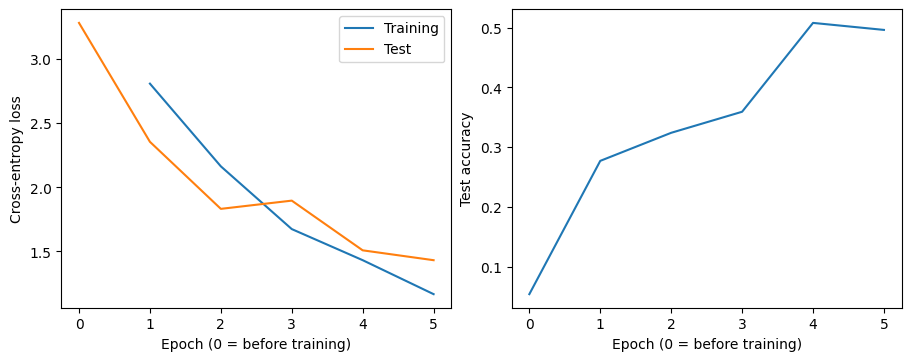

In [11]:
plot_history(history)
plt.show()

The reference run improves test accuracy from 5.5% to about 49.6% after five epochs, with loss falling from 3.283 to 1.432. Accuracy reaches 50.8% at epoch four before falling slightly, even though cross-entropy continues to fall. The two measures ask different questions: whether the winning class is correct, and how much probability the model assigns to the correct label.

This is a short learning demonstration on selected recordings, rather than a converged result for the full dataset. We use the held-out split to inspect learning here; repeated tuning against it would require another validation split before making a final performance claim.

For an experiment, change only the horizon range in a fresh run, keeping the subset and seed fixed. A shorter horizon lets early contributions fade more, while a longer horizon gives them more passive retention. Compare the decay plot and held-out curves without assuming that longer memory must improve recognition. Another useful change is the frame duration: a longer frame combines more events into each vector and produces a shorter sequence.

## 9. Saving the learned model

Each independent recording starts from reset states, so we'll save the weights and optimizer in `checkpoints/model.pt` without a state snapshot. We'll also keep the width, frame duration and initialization length so we can reconstruct the model.

In [12]:
checkpoint = checkpoint_dir / "model.pt"
torch.save({"weights": model.state_dict(), "optimizer": optimizer.state_dict(),
            "width": 64, "sequence_steps": sequence_steps, "time_window": 20000}, checkpoint)
print(checkpoint)

checkpoints/model.pt


Training and evaluation take roughly three to four seconds on CPU, plus about two seconds to frame cached data. The initial dataset download is separate and can take considerably longer.

The complete program is `python examples/shd/main.py --device cpu`. It trains with compiled evaluation between epochs, then saves figures and `checkpoints/model.pt` under `examples/shd`, while keeping downloaded recordings in the shared `examples/data` folder.